# Guidance strength

**How strongly generated child rows follow the parent-group classifier. Stronger guidance may improve relationships but reduce diversity.**

**First prerequisite:** prepare the account sample, then complete [00_baseline.ipynb](00_baseline.ipynb). No historical experiment runs or original model checkpoints are used here.

**Work required:** Generation only after the baseline; reuse its clustering, diffusion, and classifiers.

The generator's guidance classifiers predict parent groups. The separate overdraft evaluator stays fixed. You run this notebook yourself.

[Instructions and index](README.md) · [Final comparison](all_experiments.ipynb) · [Research log](PROGRESS.md)

In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    PRESETS,
    base_config,
    completed_runs,
    make_trials,
    preview_trials,
    run_trials,
)


## 1. Settings — keep the baseline fixed

Use the `.venv` kernel. Start with one training/sampling seed and a short candidate list. Keep `RUN_NEW_TRIALS = False` to preview or evaluate completed results. Enable it yourself on a GPU to run a sweep.

The baseline parameter value is included automatically even if you narrow `VALUES`; duplicates are removed. All other settings match the baseline notebook. Keep its input data, root, full sample scale, and base settings fixed. Candidate values are starting experiments, not proven optimal choices.

In [3]:
EXPERIMENT = "guidance"
RUN_NEW_TRIALS = True
SAMPLING_SEEDS = [42]
TRAINING_SEEDS = [42]
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
PARAMETER, DEFAULT_VALUES = PRESETS[EXPERIMENT]
VALUES = list(DEFAULT_VALUES)  # Narrow this list for the first sweep.

print(f"Selected processed dataset: {DATA_DIR}")


Selected processed dataset: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Preview and check the baseline

This creates no models or synthetic data. Stage IDs show logical reuse groups; completed stages are checked during execution. A model set covers all nine parent/table relations.

The baseline is included for each requested seed pair. Vary sampling seeds later to test generation variability; vary training seeds separately to test model variability.

In [5]:
TRIALS = make_trials(
    BASE, PARAMETER, VALUES, sampling_seeds=SAMPLING_SEEDS,
    training_seeds=TRAINING_SEEDS, include_baseline=True,
)
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
COUNTS = PLAN[["cluster", "diffusion", "model", "sample"]].nunique()
print(f"Planned configurations/generations: {COUNTS['sample']} (includes the baseline).")
print(f"Logical sets before cache lookup: {COUNTS['cluster']} clustering, "
      f"{COUNTS['diffusion']} diffusion, {COUNTS['model']} classifier.")
BASELINE_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=[BASE]) if DATA_DIR.is_dir() else []
if BASELINE_DIRS:
    print("Baseline found. Matching completed stages will be reused.")
else:
    print("No completed baseline yet. Run 00_baseline.ipynb before enabling this sweep.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,dc077a94e7fe0fbd916a,42,42,1.0,50
1,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,91697a10aa5d3f8a8335,42,42,0.0,50
2,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,1cdc31d7763345a2b3ee,42,42,0.5,50
3,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,6de17840fa312ebb2897,42,42,2.0,50
4,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,d790c1b3f6b69537ad02,42,42,4.0,50


Planned configurations/generations: 5 (includes the baseline).
Logical sets before cache lookup: 1 clustering, 1 diffusion, 1 classifier.
Baseline found. Matching completed stages will be reused.


## 3. Run this sweep on GPU

This step requires the completed baseline and your `RUN_NEW_TRIALS = True` setting. Compatible baseline stages are reused. Run one generating notebook at a time; retain the same experiment root across notebooks. Inspect `status.json` if a stage fails before choosing a fresh root to retry.

In [4]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    if not BASELINE_DIRS:
        raise ValueError("Create the reference run in 00_baseline.ipynb before starting this sweep.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / f"plan_{EXPERIMENT}.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_run": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.")


INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (77, 15)
INFO :      Total dataframe shape: (77, 15)
INFO :      Numerical data shape: (77, 13)
INFO :      Categorical data shape: (77, 2)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (596, 4)
INFO :      Total dataframe shape: (596, 4)
INFO :      Numerical data shape: (596, 0)
INFO :      Categorical data shape: (596, 4)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (500, 2)
INFO :      Total dataframe shape: (500, 2)
INFO :      Numerical data shape: (500, 1)
INFO :      Categorical data shape: (500, 1)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (596, 1)
INFO :      Total dataframe shape: (596, 

,saved_run
0,/home/coder/synthetic-data-bootcamp/implementa...
1,/home/coder/synthetic-data-bootcamp/implementa...
2,/home/coder/synthetic-data-bootcamp/implementa...
3,/home/coder/synthetic-data-bootcamp/implementa...
4,/home/coder/synthetic-data-bootcamp/implementa...


## 4. Evaluate completed results on CPU

A single real-trained overdraft detector evaluates the baseline and completed variants in this call. An early preview may show just the baseline; incomplete sweeps are not presented as complete comparisons.

Compare event counts, AP/prevalence/uncertainty, overall and overdraft-only distributions, account integrity, and chronology. A high raw synthetic AP alone does not establish the best data.

The same report also scores all 8 tables and 8 parent/child edges: column distributions, missing/unknown values, within/cross-table relationships, cardinalities, and PK/FK integrity. It checks client/account combinations through `disp`. The full-table and overdraft score groups remain separate; no combined winner score is used.

Evaluating 5e1ee60aff45370f4680
Evaluating 9d1bd199c0b8ffe393c4
Evaluating a3860d6c1335b858616c
Evaluating d32c2dce062b79cbbdc4
Evaluating e7a4c18ed1c24b395ec4


,parameter_value,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,,
real_test,NaN,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
5e1ee60aff45370f4680,0.0,0.0068,0.0058,0.0083,0.0039,0.0030,0.0502,0.0238,0.4097,0.2074
9d1bd199c0b8ffe393c4,0.5,0.0068,0.0059,0.0094,0.0041,0.0028,0.0562,0.0232,0.4181,0.1977
a3860d6c1335b858616c,2.0,0.0067,0.0057,0.0081,0.0031,0.0037,0.0758,0.0237,0.3354,0.1864
d32c2dce062b79cbbdc4,1.0,0.0059,0.0052,0.0071,0.0033,0.0031,0.0589,0.0229,0.3829,0.1900
e7a4c18ed1c24b395ec4,4.0,0.0122,0.0103,0.0158,0.0033,0.0062,0.1227,0.0279,0.2927,0.2268


Detailed report: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/e137bf61d4d4fdb2


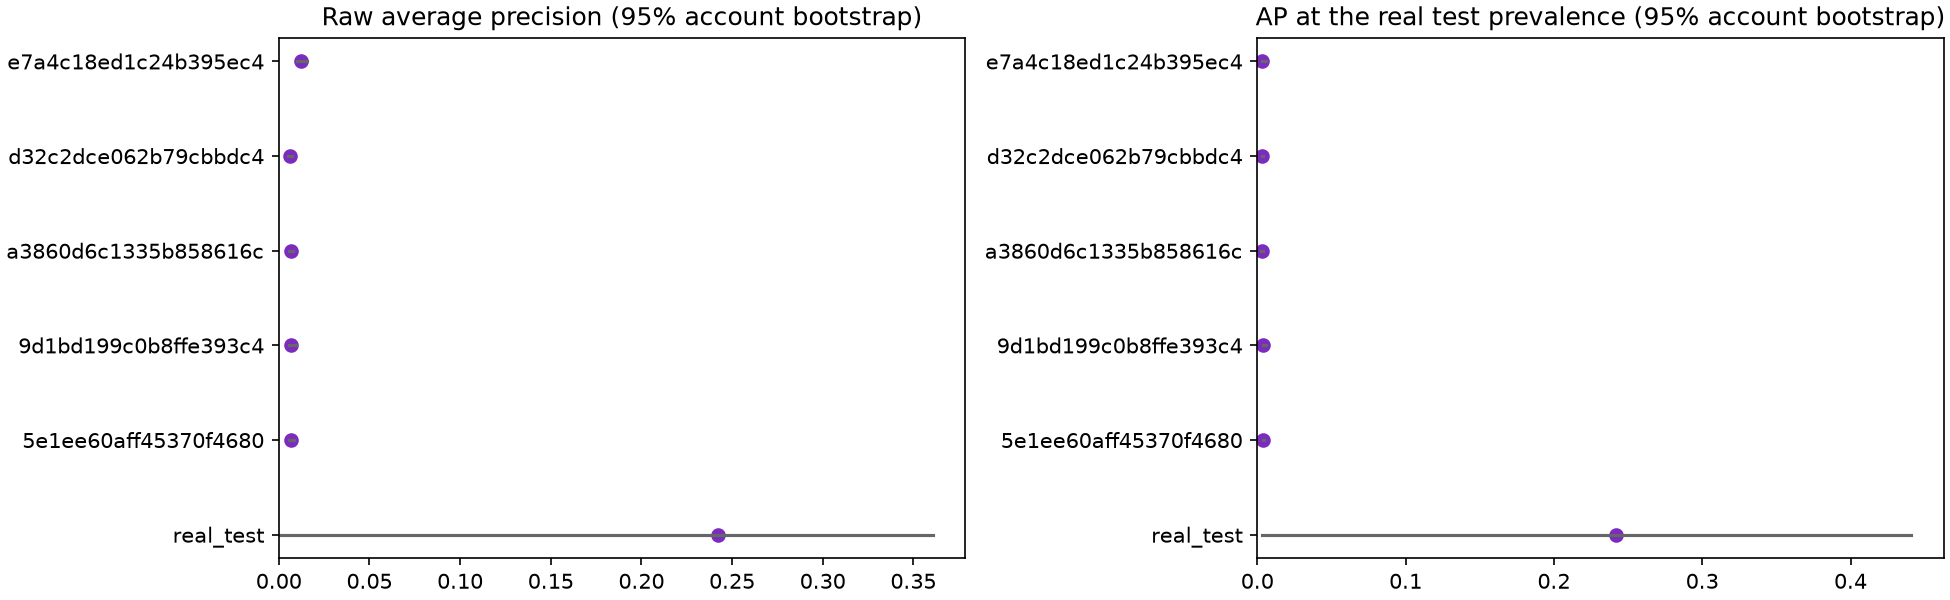

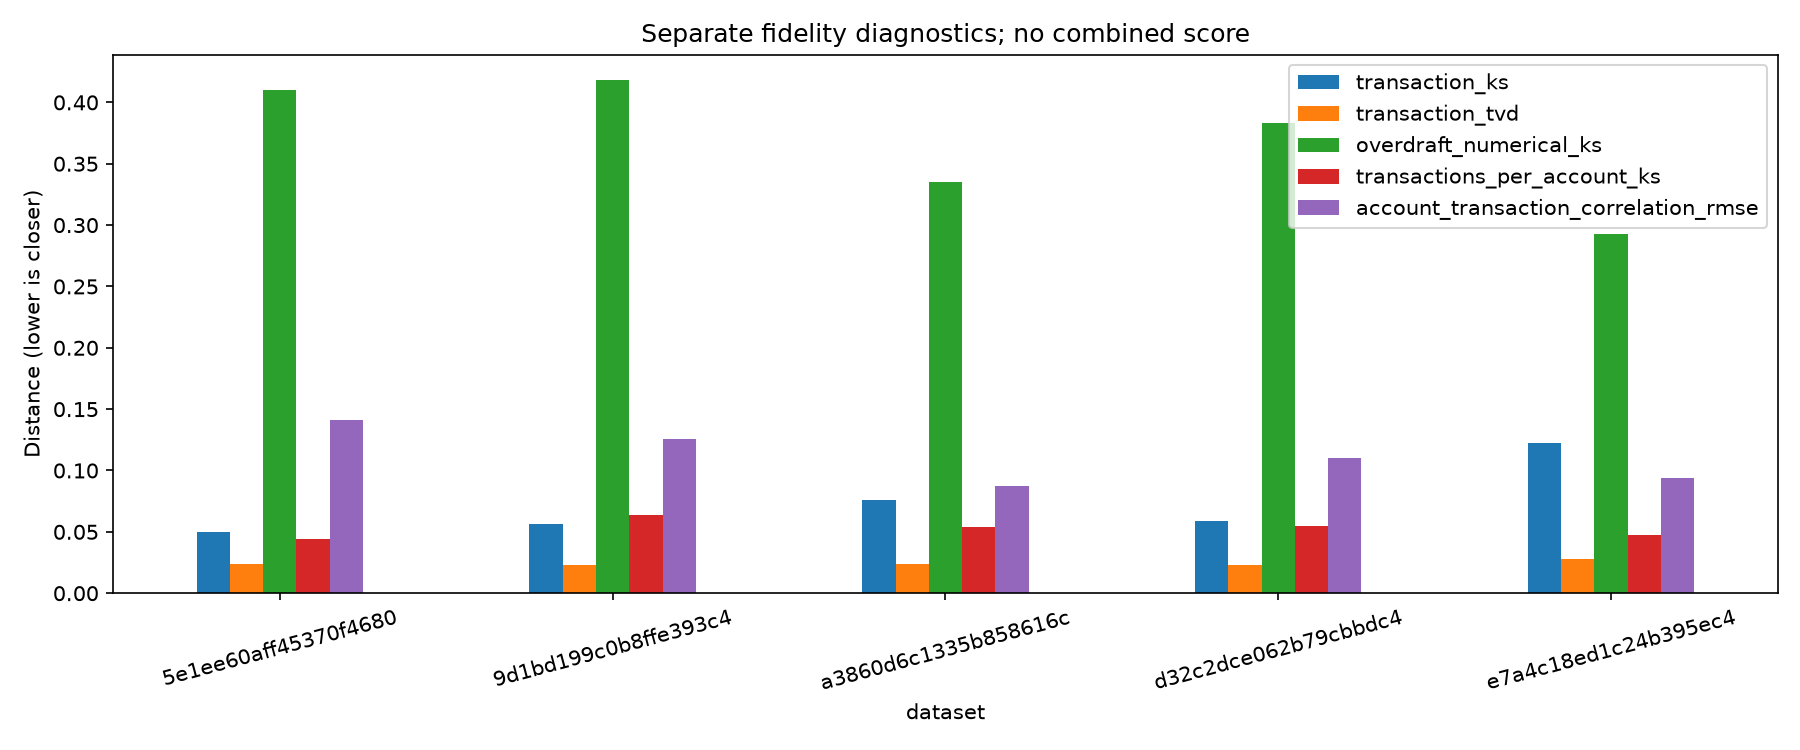

Completed 5 of 5 requested seed/configuration pairs.
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
5e1ee60aff45370f4680,8.0,8.0,0.0949,0.0879,0.0804,NaN,1.0,1.0,0.0175,0.1496,0.0,2.0
9d1bd199c0b8ffe393c4,8.0,8.0,0.0887,0.0938,0.0825,NaN,1.0,1.0,0.0328,0.1479,0.0,2.0
a3860d6c1335b858616c,8.0,8.0,0.0977,0.1076,0.0820,NaN,1.0,1.0,0.0404,0.1787,0.0,2.0
d32c2dce062b79cbbdc4,8.0,8.0,0.0914,0.1043,0.0829,NaN,1.0,1.0,0.0649,0.1641,0.0,2.0
e7a4c18ed1c24b395ec4,8.0,8.0,0.1244,0.1226,0.0917,NaN,1.0,1.0,0.0330,0.2141,0.0,2.0


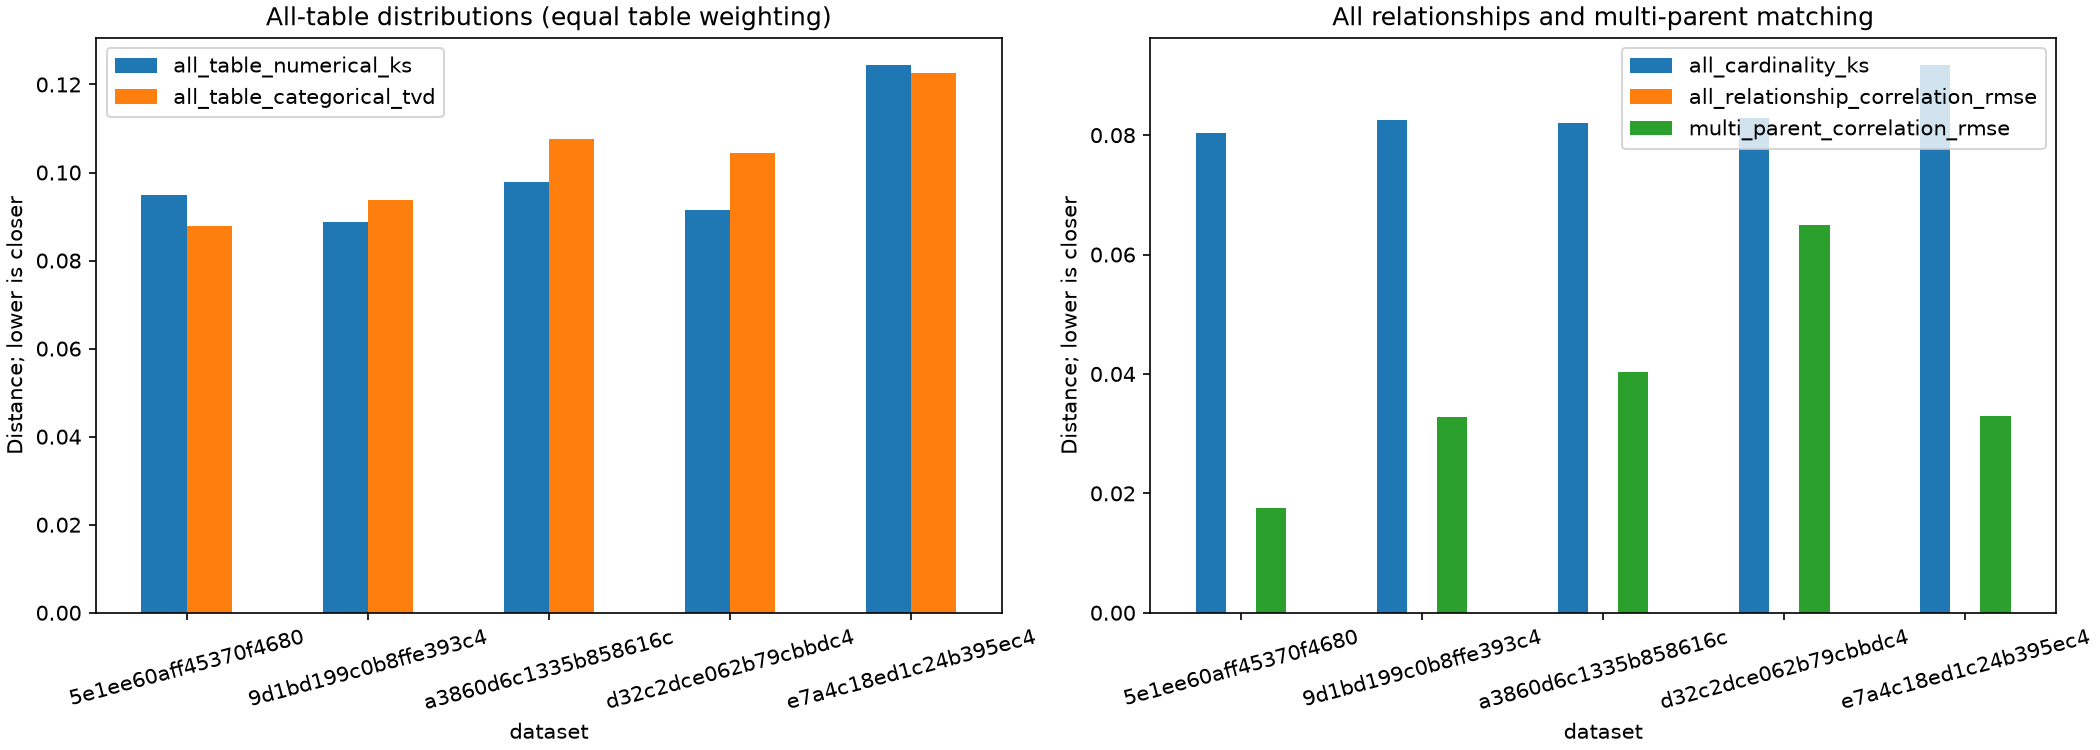

In [6]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    section, field = PARAMETER.split(".")
    parameter_values = {}
    for run in RUN_DIRS:
        saved = yaml.safe_load((run / "config.yaml").read_text())
        parameter_values[run.name] = str(saved[section][field])
    comparison.insert(0, "parameter_value", pd.Series(parameter_values))
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[["parameter_value", *TRANSFER_AND_QUALITY]].round(4))
    print(f"Detailed report: {REPORT_DIR}")
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Completed {len(RUN_DIRS)} of {len(TRIALS)} requested seed/configuration pairs.")
else:
    print("No completed results for this experiment. Start with 00_baseline.ipynb.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Conclusion — completed guidance sweep

**Decision: retain guidance 0 and 0.5 as candidates; keep guidance 1 as the frozen baseline. No overall winner is established. Investigate account behaviour and timing before expanding the sweeps.**

All five settings (**0, 0.5, 1, 2, 4**) completed on the same 500-account cohort, with training/sampling seeds **42/42**, full sample scale, and the baseline's trained models reused. Only guidance strength changed. One real-trained overdraft detector and account split evaluated all runs; this is real→synthetic transfer, not synthetic-trained→real utility.

### Overdraft transfer

| Guidance | Raw AP ↑ | Prevalence-adjusted AP ↑ | ROC-AUC ↑ | Overdraft rows | Overdraft prevalence |
| --- | ---: | ---: | ---: | ---: | ---: |
| 0 | 0.00684 | 0.00390 | 0.6664 | 331 | 0.2952% |
| 0.5 | 0.00682 | 0.00407 | 0.6678 | 330 | 0.2816% |
| 1 (baseline) | 0.00595 | 0.00327 | 0.6249 | 351 | 0.3054% |
| 2 | 0.00675 | 0.00307 | 0.6156 | 431 | 0.3694% |
| 4 | 0.01220 | 0.00333 | 0.6244 | 716 | 0.6246% |

Higher AP/ROC-AUC is better. Prevalence-adjusted AP puts every run at the same real-test overdraft frequency so a run does not look better simply because it contains more overdrafts. Real-test AP is **0.2422** and ROC-AUC **0.8722**; full-real-cohort overdraft prevalence is **0.2101%**.

- **0.5 has the highest adjusted AP and ROC-AUC point estimates.** Its adjusted AP is about 24% above baseline, but still low; the bootstrap intervals overlap and there is only one generation per setting. This is a candidate for later confirmation, not a proven improvement.
- **4 has the highest raw AP, but no comparable adjusted gain.** Overdraft prevalence rises to 0.6246%; adjusted AP is 0.00333 versus baseline 0.00327, and ROC-AUC is essentially unchanged. The raw AP increase alone does not justify selecting it.

### Distribution and account-behaviour tradeoffs

| Guidance | Transaction numerical KS ↓ | All-table numerical KS ↓ | All-table categorical TVD ↓ | Accounts ever overdrawn | Transactions before account opening |
| --- | ---: | ---: | ---: | ---: | ---: |
| 0 | 0.0502 | 0.0949 | 0.0879 | 49.5% | 20.7% |
| 0.5 | 0.0562 | 0.0887 | 0.0938 | 46.5% | 19.8% |
| 1 (baseline) | 0.0589 | 0.0914 | 0.1043 | 45.8% | 19.0% |
| 2 | 0.0758 | 0.0977 | 0.1076 | 47.3% | 18.6% |
| 4 | 0.1227 | 0.1244 | 0.1226 | 48.2% | 22.7% |

Lower KS/TVD means closer distributions, not automatically useful data. In the real cohort, **5.6%** of accounts ever overdraw and **0%** of transactions precede account opening.

- **0 best preserves overall numerical transaction distributions; 0.5 has the lowest all-table numerical KS.** Setting 0 also has the lowest all-table categorical TVD and cardinality KS. Baseline 1 retains the lowest transaction categorical TVD and the smallest account-overdraft-rate discrepancy, although that discrepancy remains large.
- **Stronger guidance changes the tradeoff rather than fixing it.** Setting 4 improves overdraft-only numerical KS (0.2927 versus baseline 0.3829), but worsens overall transaction numerical KS, all-table numerical/categorical distributions, and chronology. Setting 2 has the lowest pre-opening transaction rate (18.6%), which is still inconsistent with the reference.
- **Account behaviour remains the main unresolved issue across all settings:** 45.8–49.5% of accounts overdraw and 18.6–22.7% of transactions precede account opening. All eight tables/edges have valid measured PK/FK checks; those checks do not establish realistic account histories. The two undefined `disp→card` association pairs still make global relationship RMSE missing; do not interpret it as zero error.

### Limits and next decision

The real test contains overdrafts in only **5 accounts**, giving a wide real AP interval (0.0005–0.3606). The 200 account-bootstrap draws describe uncertainty conditional on this fitted detector and saved generation; they do not measure variation across training or generation seeds. The results do not establish a precise real→synthetic transfer-gap magnitude or a reliable ranking across seeds.

**Next: inspect existing before/after-matching artifacts and trace date alignment, account conditioning, and transaction assignment.** These are hypotheses to investigate, not established causes. Preserve every run and the baseline; defer broader clustering/training sweeps. After the audit, reconsider repeat runs of 0/0.5 against matched baseline controls. No new notebook execution is needed to record this conclusion.

Saved evidence: [comparison.csv](../results/experiments/transaction_overdraft_from_scratch/e137bf61d4d4fdb2/comparison.csv), [transfer intervals](../results/experiments/transaction_overdraft_from_scratch/e137bf61d4d4fdb2/transfer_intervals.png), and [full-table quality](../results/experiments/transaction_overdraft_from_scratch/e137bf61d4d4fdb2/multi_table_quality.png). Run IDs and recorded timings are in [PROGRESS.md](PROGRESS.md).
